In [3]:
import sys
print(sys.executable)

c:\Users\mazlu\anaconda3\envs\ppg312\python.exe


In [10]:

from scipy.io import loadmat    # used to turn .mat files into numpy Arrays
import os
import matplotlib.pyplot as plt
import numpy as np

def plot_ABP_PPG_signal(ABP, PPG, fs):

    t = np.arange(len(PPG)) / fs    # time axis, in seconds 
    
    plt.figure(figsize=(12,6))

    plt.subplot(2,1,1)
    plt.plot(t, ABP, color='blue')
    plt.title('ABP Signal')
    plt.xlabel('Time [s]')
    plt.ylabel('Normalized ABP ([0,1])')

    plt.subplot(2,1,2)
    plt.plot(t, PPG, color='red')
    plt.title('PPG Signal')
    plt.xlabel('Time [s]')
    plt.ylabel('Light Intensity [V]')

    plt.tight_layout()

    plt.show()

5857
Datapoint 0:
dict_keys(['__header__', '__version__', '__globals__', 'signal_processing'])
accessing struct 0:
[0.73313783 0.72434018 0.71358749 ... 0.27370479 0.26979472 0.6969697 ]
[69.03524709 68.64411255 68.252978   ... 61.79925802 66.8840071
 78.03134161]
1876


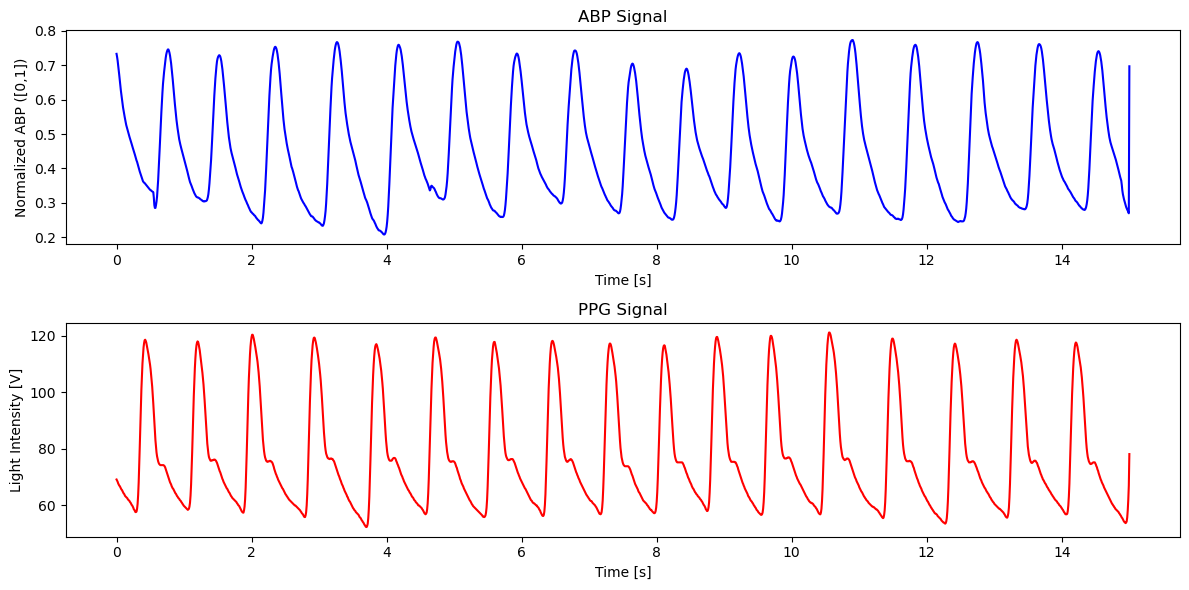

struct_features: ('ppg', 'abp', 'beats_abp', 'mean_pulse_abp')
struct_stats_features: ('ppg', 'abp', 'maen_abp')
delineator: ('PPG', 'ABP')
[[array([[(array([[  36,  132,  234,  348,  462,  572,  681,  790,  895,  996, 1094,
                  1193, 1302, 1418, 1533, 1648, 1759]], dtype=uint16), array([[  53,  150,  252,  366,  481,  590,  700,  807,  914, 1014, 1112,
                  1212, 1320, 1437, 1552, 1666, 1777]], dtype=uint16), array([[  86,  178,  284,  398,  509,  623,  728,  837,  946, 1045, 1144,
                  1241, 1350, 1469, 1582, 1697]], dtype=uint16))                                                                                ]],
        dtype=[('foot', 'O'), ('SysPeak', 'O'), ('DicroN', 'O')])                                                                                  ]]


In [ ]:
data_path = 'ABP_PPG'
data_file = sorted(os.listdir(data_path))
print(len(data_file))
fs = 125
for i in range(1):
    print(f'Datapoint {i}:')
    file_path = os.path.join(data_path, data_file[i])
    data = loadmat(file_path)
    print(data.keys())
    # print(data['signal_processing'].shape)
    # sp = data['signal_processing']
    # print(type(sp))
    # print(sp.shape)
    # print(sp.dtype.names)
    for j in range(1):
        print(f'accessing struct {j}:')
        sp = data['signal_processing'][0,j] # access first struct

        # print(f'type: {sp.dtype.names}')

        # Signal
        segment = sp['signal']
        # print(segment)
        ABP = segment[0]
        PPG = segment[1]
        print(ABP)
        print(len(ABP)) # the signals are just 1D arrays of size 1876 where each idnex is its associated value
        plot_ABP_PPG_signal(ABP,PPG,fs)

        # index
        idx = sp['index']

        # struct_features
        feat = sp['struct_features']
        print(f'struct_features: {feat.dtype.names}')
        ppg = feat['ppg']
        abp = feat['abp']
        beats_abp = feat['beats_abp']
        # print(beats_abp[0][0][10])
        # print(beats_abp[0][0].shape)
        # mean_pulse_abp = feat['mean_pulse_abp']
        # print(mean_pulse_abp[0][0].shape)

        # struct_stats_features
        featStats = sp['struct_stats_features']
        print(f'struct_stats_features: {featStats.dtype.names}')
        ppgStats = featStats['ppg']
        abpStats = featStats['abp']
        maen_abp = featStats['maen_abp']

        # delineator
        delineator = sp['struct_delineator']
        print(f'delineator: {delineator.dtype.names}')
        del_abp = delineator['ABP']
        print(del_abp)






